<a href="https://colab.research.google.com/github/saratyulyuova/tenge-ruble-network/blob/main/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tenge and Ruble in the Emerging-Market Currency Network, 2015–2026
**Author:** Sara Tyulyuova

**Question:** How did the network position of the Kazakhstani tenge relative to the Russian ruble change after 24 February 2022?

**H₀:** the correlation-based distance between KZT and RUB is the same before and after 24 Feb 2022. **H₁:** it changed (two-sided).

Data preparation (download, cleaning, verification against official NBK and Bank of Russia rates) is in `network_analysis.ipynb`.

## 1. Data

In [3]:
!pip install -q networkx
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx, os
import requests, time, io
import xml.etree.ElementTree as ET
from scipy.stats import norm

BASE = "https://raw.githubusercontent.com/saratyulyuova/tenge-ruble-network/refs/heads/main/data"
prices = pd.read_csv(f"{BASE}/raw_prices.csv", index_col=0, parse_dates=True)
fac = pd.read_csv(f"{BASE}/factors.csv", index_col=0, parse_dates=True)
FIG = "figures"; os.makedirs(FIG, exist_ok=True)
print("prices:", prices.shape, "| factors:", fac.shape)

prices: (2909, 25) | factors: (2909, 3)


In [4]:
dates = pd.date_range("2015-09-02", "2026-09-30", freq="W-WED")
rows, failed = [], []
for i, d in enumerate(dates):
    url = f"https://nationalbank.kz/rss/get_rates.cfm?fdate={d:%d.%m.%Y}"
    try:
        r = requests.get(url, timeout=20, headers={"User-Agent": "Mozilla/5.0"})
        for item in ET.fromstring(r.content).iter("item"):
            if item.findtext("title") == "USD":
                rows.append((d, float(item.findtext("description")) / float(item.findtext("quant"))))
                break
    except Exception:
        failed.append(d.date())
    if i % 100 == 0:
        print(f"{i} of {len(dates)}")
    time.sleep(0.2)
kzt_off = pd.Series(dict(rows)).sort_index()
print("KZT official:", len(kzt_off), "Wednesdays | failed:", len(failed))

0 of 579
100 of 579
200 of 579
300 of 579
400 of 579
500 of 579
KZT official: 575 Wednesdays | failed: 0


In [5]:
url = ("https://www.cbr.ru/scripts/XML_dynamic.asp"
       "?date_req1=01/08/2015&date_req2=30/09/2026&VAL_NM_RQ=R01235")
resp = requests.get(url, timeout=60, headers={"User-Agent": "Mozilla/5.0"})
cbr = pd.read_xml(io.BytesIO(resp.content), xpath=".//Record", parser="etree")
rub_off = pd.Series(
    cbr["Value"].astype(str).str.replace(",", ".").astype(float).values / cbr["Nominal"].values,
    index=pd.to_datetime(cbr["Date"], format="%d.%m.%Y"),
).sort_index()

def shift_back(s):
    """Bank of Russia sets the rate for day X on the previous business day."""
    s2 = s.copy(); s2.index = s2.index - pd.offsets.BDay(1)
    return s2[~s2.index.duplicated(keep="first")].sort_index()

print("RUB official:", len(rub_off), "days")

RUB official: 2758 days


In [6]:
# replace Yahoo KZT and RUB with official rates (decision from data verification)
prices_final = prices.copy()
prices_final["KZT"] = kzt_off.reindex(prices_final.index, method="ffill")
prices_final["RUB"] = shift_back(rub_off).reindex(prices_final.index, method="ffill")

def to_weekly_returns(p):
    w = p.loc["2015-08-26":].resample("W-WED").last().drop(columns="GOLD")
    return (-np.log(w).diff()).dropna()          # "+" = currency strengthened vs USD

R = to_weekly_returns(prices_final)               # main version (official KZT, RUB)
R_yahoo = to_weekly_returns(prices)               # all-Yahoo version, for robustness
F = np.log(fac.loc["2015-08-26":].resample("W-WED").last()).diff().dropna()
R, F = R.align(F, join="inner", axis=0)
R_yahoo = R_yahoo.reindex(R.index)

BREAK = "2022-02-24"
pre, post = R.loc[:"2022-02-23"], R.loc[BREAK:]
F_pre, F_post = F.loc[pre.index], F.loc[post.index]
print("Weeks:", len(R), "| before:", len(pre), "| after:", len(post), "| currencies:", R.shape[1])

Weeks: 578 | before: 338 | after: 240 | currencies: 24


## 2. Minimum spanning trees before and after 2022

In [7]:
def dist(X):
    return np.sqrt(2 * (1 - X.corr()))          # Mantegna (1999) distance

def mst(X):
    D = dist(X)
    G = nx.Graph()
    cols = list(D.columns)
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            G.add_edge(cols[i], cols[j], weight=D.iloc[i, j])
    return nx.minimum_spanning_tree(G), D        # Kruskal's algorithm

T_pre, D_pre = mst(pre)
T_post, D_post = mst(post)
print("Edges in each tree:", T_pre.number_of_edges(), T_post.number_of_edges())

Edges in each tree: 23 23


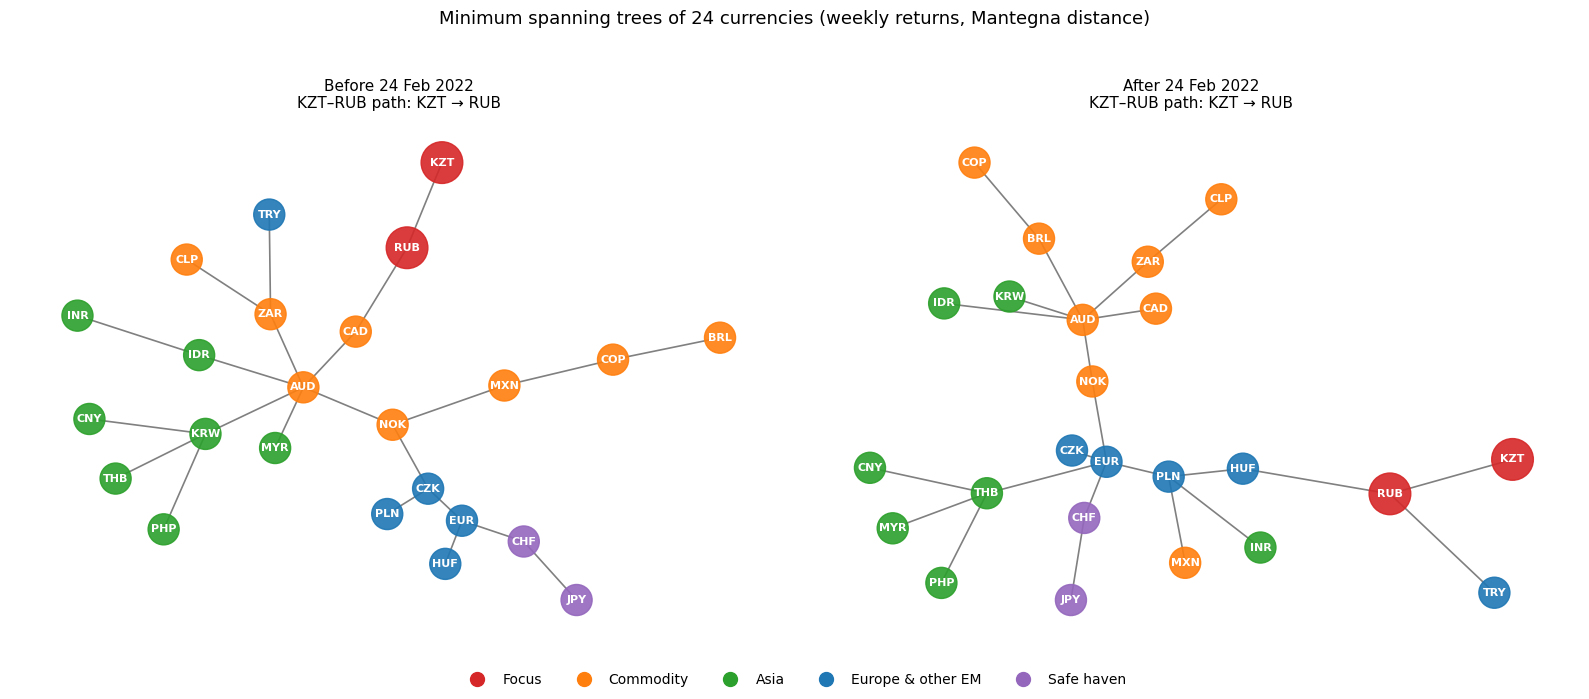

In [8]:
groups = {
    "KZT": "Focus", "RUB": "Focus",
    "NOK": "Commodity", "CAD": "Commodity", "AUD": "Commodity", "BRL": "Commodity",
    "ZAR": "Commodity", "CLP": "Commodity", "COP": "Commodity", "MXN": "Commodity",
    "CNY": "Asia", "INR": "Asia", "IDR": "Asia", "KRW": "Asia", "THB": "Asia", "MYR": "Asia", "PHP": "Asia",
    "EUR": "Europe & other EM", "PLN": "Europe & other EM", "HUF": "Europe & other EM",
    "CZK": "Europe & other EM", "TRY": "Europe & other EM",
    "JPY": "Safe haven", "CHF": "Safe haven",
}
colors = {"Focus": "#d62728", "Commodity": "#ff7f0e", "Asia": "#2ca02c",
          "Europe & other EM": "#1f77b4", "Safe haven": "#9467bd"}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, T, title in [(axes[0], T_pre, "Before 24 Feb 2022"), (axes[1], T_post, "After 24 Feb 2022")]:
    pos = nx.kamada_kawai_layout(T)
    nc = [colors[groups[n]] for n in T.nodes]
    ns = [900 if n in ("KZT", "RUB") else 500 for n in T.nodes]
    nx.draw_networkx_edges(T, pos, ax=ax, edge_color="gray", width=1.2)
    nx.draw_networkx_nodes(T, pos, ax=ax, node_color=nc, node_size=ns, alpha=0.9)
    nx.draw_networkx_labels(T, pos, ax=ax, font_size=8, font_color="white", font_weight="bold")
    path = nx.shortest_path(T, "KZT", "RUB")
    ax.set_title(f"{title}\nKZT–RUB path: {' → '.join(path)}", fontsize=11)
    ax.axis("off")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, markersize=10, label=g) for g, c in colors.items()]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False)
plt.suptitle("Minimum spanning trees of 24 currencies (weekly returns, Mantegna distance)", fontsize=13)
plt.tight_layout(rect=(0, 0.05, 1, 0.95))
plt.savefig(f"{FIG}/fig3_mst_before_after.png", dpi=200)
plt.show()

In [9]:
def tree_stats(T, D, label):
    btw = nx.betweenness_centrality(T)
    return {
        "period": label,
        "d(KZT,RUB)": round(D.loc["KZT", "RUB"], 3),
        "corr(KZT,RUB)": round(1 - D.loc["KZT", "RUB"] ** 2 / 2, 3),
        "KZT–RUB steps in tree": nx.shortest_path_length(T, "KZT", "RUB"),
        "KZT neighbours": ", ".join(sorted(T.neighbors("KZT"))),
        "RUB neighbours": ", ".join(sorted(T.neighbors("RUB"))),
        "KZT betweenness": round(btw["KZT"], 3),
        "RUB betweenness": round(btw["RUB"], 3),
        "mean edge length": round(np.mean([w for _, _, w in T.edges(data="weight")]), 3),
    }
table2 = pd.DataFrame([tree_stats(T_pre, D_pre, "before"),
                       tree_stats(T_post, D_post, "after")]).set_index("period").T
table2.to_csv(f"{FIG}/table2_network.csv")
table2

period,before,after
"d(KZT,RUB)",1.08,1.102
"corr(KZT,RUB)",0.417,0.393
KZT–RUB steps in tree,1,1
KZT neighbours,RUB,RUB
RUB neighbours,"CAD, KZT","HUF, KZT, TRY"
KZT betweenness,0.0,0.0
RUB betweenness,0.087,0.17
mean edge length,0.906,0.869


## 3. External factors and hypothesis test

In [10]:
def factor_resid(Rp, Fp):
    """OLS of each currency on [1, OIL, DXY, VIX]; returns residuals, betas, R²."""
    X = np.column_stack([np.ones(len(Fp)), Fp.values])
    B, *_ = np.linalg.lstsq(X, Rp.values, rcond=None)
    E = Rp.values - X @ B
    resid = pd.DataFrame(E, index=Rp.index, columns=Rp.columns)
    betas = pd.DataFrame(B[1:].T, index=Rp.columns, columns=Fp.columns)
    r2 = pd.Series(1 - E.var(axis=0) / Rp.values.var(axis=0), index=Rp.columns)
    return resid, betas, r2

E_pre, B_pre, R2_pre = factor_resid(pre, F_pre)
E_post, B_post, R2_post = factor_resid(post, F_post)
table3 = pd.concat({
    "before": pd.concat([B_pre.loc[["KZT", "RUB"]], R2_pre[["KZT", "RUB"]].rename("R2")], axis=1),
    "after":  pd.concat([B_post.loc[["KZT", "RUB"]], R2_post[["KZT", "RUB"]].rename("R2")], axis=1),
}).round(3)
table3.to_csv(f"{FIG}/table3_factor_betas.csv")
table3

OIL    DXY    VIX     R2
before KZT  0.103 -0.285  0.008  0.176
       RUB  0.108 -0.317 -0.016  0.207
after  KZT  0.020 -0.152 -0.016  0.040
       RUB -0.027 -0.738  0.004  0.036

RAW:      Δd = +0.022  95% CI [-0.044, +0.473]  p ≈ 0.092  | Fisher p = 0.732
FACTORS:  Δd = -0.072  95% CI [-0.123, +0.358]  p ≈ 0.255


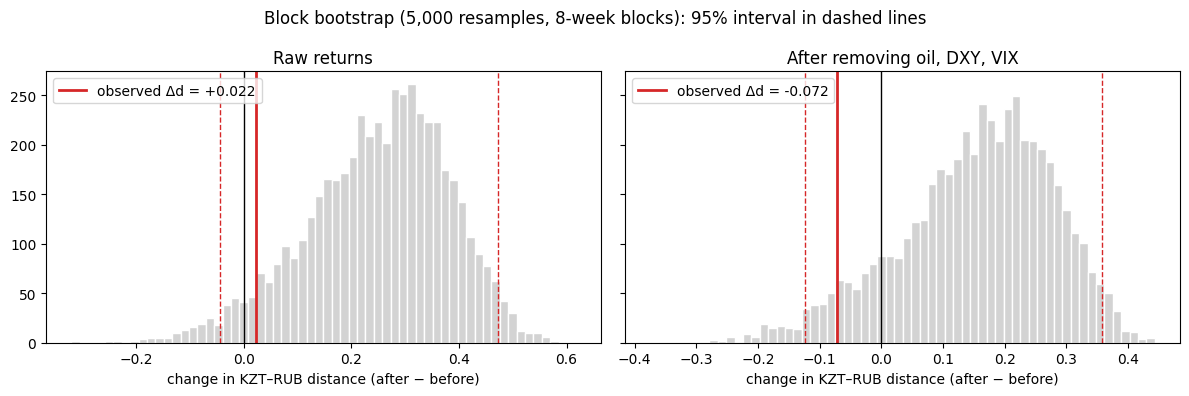

In [11]:
rng = np.random.default_rng(42)

def d_kr(X, Fx=None):
    X = X[["KZT", "RUB"]]
    if Fx is not None:
        X, _, _ = factor_resid(X, Fx)       # re-estimate factors inside every resample
    return np.sqrt(2 * (1 - X["KZT"].corr(X["RUB"])))

def block_idx(n, b):
    starts = rng.integers(0, n - b + 1, size=int(np.ceil(n / b)))
    return np.concatenate([np.arange(s, s + b) for s in starts])[:n]

def boot_test(A, B_, FA=None, FB=None, b=8, n_boot=5000):
    delta = d_kr(B_, FB) - d_kr(A, FA)
    sims = np.empty(n_boot)
    for k in range(n_boot):
        ia, ib = block_idx(len(A), b), block_idx(len(B_), b)
        sims[k] = (d_kr(B_.iloc[ib], None if FB is None else FB.iloc[ib])
                   - d_kr(A.iloc[ia], None if FA is None else FA.iloc[ia]))
    lo, hi = np.percentile(sims, [2.5, 97.5])
    p = min(1.0, 2 * min((sims <= 0).mean(), (sims >= 0).mean()))
    return delta, lo, hi, p, sims

def fisher(A, B_):
    r1, r2 = A["KZT"].corr(A["RUB"]), B_["KZT"].corr(B_["RUB"])
    z = (np.arctanh(r2) - np.arctanh(r1)) / np.sqrt(1 / (len(A) - 3) + 1 / (len(B_) - 3))
    return 2 * (1 - norm.cdf(abs(z)))

delta, lo, hi, p, sims = boot_test(pre, post)
print(f"RAW:      Δd = {delta:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  p ≈ {p:.3f}  | Fisher p = {fisher(pre, post):.3f}")
delta_e, lo_e, hi_e, p_e, sims_e = boot_test(pre, post, F_pre, F_post)
print(f"FACTORS:  Δd = {delta_e:+.3f}  95% CI [{lo_e:+.3f}, {hi_e:+.3f}]  p ≈ {p_e:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, s, d0, l, h, t in [(ax[0], sims, delta, lo, hi, "Raw returns"),
                          (ax[1], sims_e, delta_e, lo_e, hi_e, "After removing oil, DXY, VIX")]:
    a.hist(s, bins=60, color="lightgray", edgecolor="white")
    a.axvline(0, color="black", lw=1)
    a.axvline(d0, color="#d62728", lw=2, label=f"observed Δd = {d0:+.3f}")
    a.axvline(l, color="#d62728", ls="--", lw=1); a.axvline(h, color="#d62728", ls="--", lw=1)
    a.set_title(t); a.set_xlabel("change in KZT–RUB distance (after − before)"); a.legend()
plt.suptitle("Block bootstrap (5,000 resamples, 8-week blocks): 95% interval in dashed lines")
plt.tight_layout(); plt.savefig(f"{FIG}/fig5_bootstrap.png", dpi=200); plt.show()

## 4. Results
- **Network:** the ruble is the tenge's nearest neighbour in the minimum spanning tree both before and after 24 Feb 2022 (KZT–RUB path = 1 step in both periods).
- **Correlation:** 0.417 before vs 0.393 after (distance 1.080 → 1.102).
- **Test (block bootstrap, 5,000 resamples, 8-week blocks):** raw returns Δd = +0.022, 95% CI [−0.044, +0.473]; after removing oil, DXY and VIX Δd = −0.072, 95% CI [−0.123, +0.358]. Both intervals contain zero → **no statistically significant change** in tenge–ruble co-movement.
- **What changed:** the ruble's own position. Its neighbours moved from CAD (commodity currencies) to HUF and TRY (emerging Europe), and its betweenness doubled (0.087 → 0.170). The mean edge length fell (0.906 → 0.869): currencies overall moved more together after 2022.
- **Note:** bootstrap intervals are skewed because the KZT–RUB correlation is driven by a few extreme weeks (heavy tails); the confidence interval, not the p-value, is used for the conclusion.

In [13]:
import shutil
from google.colab import files
shutil.make_archive("figures", "zip", FIG)
files.download("figures.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>